In [ ]:
# 1. Load the Iris dataset into a DataFrame.

from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

# create a new column to add the flower species name
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [13]:
# 2. Display the first 10 rows, shape, columns, missing values, and descriptive statistics.

print("First 10 rows:")
print(df.head(10))

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
print(df.describe())

First 10 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setosa  
8  seto

In [14]:
# 3. Create at least two new derived columns.
df["petal_area"] = df["petal length (cm)"] * df["petal width (cm)"]

df["sepal_area"] = df["sepal length (cm)"] * df["sepal width (cm)"]

df["petal_to_sepal_area"] = df["petal_area"] / df["sepal_area"]

df["length_difference"] = (
    df["petal length (cm)"] - df["sepal length (cm)"]
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,petal_area,sepal_area,petal_to_sepal_area,length_difference
0,5.1,3.5,1.4,0.2,setosa,0.28,17.85,0.015686,-3.7
1,4.9,3.0,1.4,0.2,setosa,0.28,14.70,0.019048,-3.5
2,4.7,3.2,1.3,0.2,setosa,0.26,15.04,0.017287,-3.4
3,4.6,3.1,1.5,0.2,setosa,0.30,14.26,0.021038,-3.1
4,5.0,3.6,1.4,0.2,setosa,0.28,18.00,0.015556,-3.6


In [18]:
# 4. Create three filtered DataFrames.

setosa_df = df[df["species"] == "setosa"]

large_petals_df = df[df["petal length (cm)"] > 4]

large_sepals_df = df[df["sepal length (cm)"] > 6]


large_petals_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,petal_area,sepal_area,petal_to_sepal_area,length_difference
50,7.0,3.2,4.7,1.4,versicolor,6.58,22.40,0.293750,-2.3
51,6.4,3.2,4.5,1.5,versicolor,6.75,20.48,0.329590,-1.9
52,6.9,3.1,4.9,1.5,versicolor,7.35,21.39,0.343619,-2.0
54,6.5,2.8,4.6,1.5,versicolor,6.90,18.20,0.379121,-1.9
55,5.7,2.8,4.5,1.3,versicolor,5.85,15.96,0.366541,-1.2
...,...,...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica,11.96,20.10,0.595025,-1.5
146,6.3,2.5,5.0,1.9,virginica,9.50,15.75,0.603175,-1.3
147,6.5,3.0,5.2,2.0,virginica,10.40,19.50,0.533333,-1.3
148,6.2,3.4,5.4,2.3,virginica,12.42,21.08,0.589184,-0.8


In [24]:
# 5. Use groupby() to compare at least two features by species.

df.groupby("species")[["sepal length (cm)", "petal length (cm)"]].mean()

,sepal length (cm),petal length (cm)
species,,
setosa,5.006,1.462
versicolor,5.936,4.260
virginica,6.588,5.552


In [25]:
df.groupby("species")[["petal_area", "sepal_area"]].mean()

,petal_area,sepal_area
species,,
setosa,0.3656,17.2578
versicolor,5.7204,16.5262
virginica,11.2962,19.6846


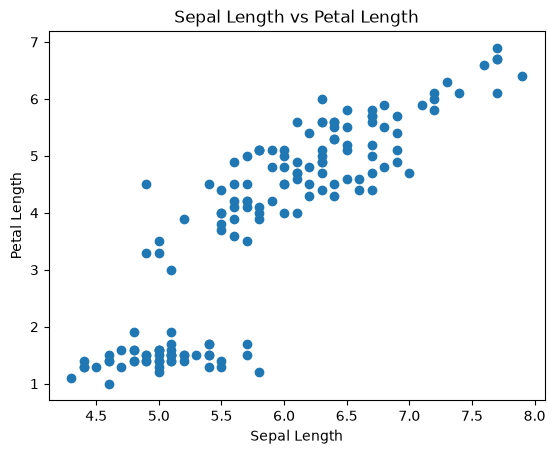

In [31]:
# 6. Create one Matplotlib scatter plot and one Matplotlib histogram.

import matplotlib.pyplot as plt

plt.scatter(
  df["sepal length (cm)"],
  df["petal length (cm)"],  
)

plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")
plt.title("Sepal Length vs Petal Length")
plt.show()

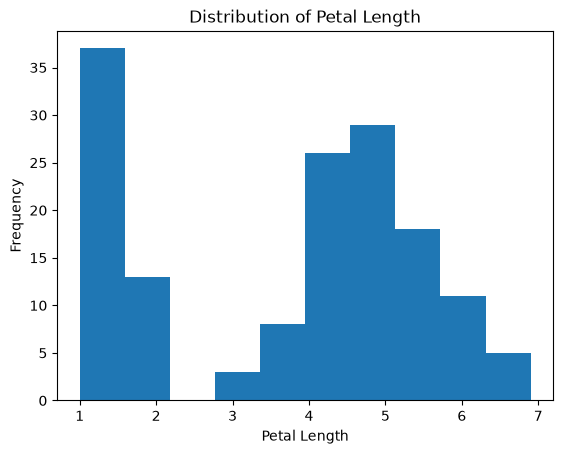

In [32]:
plt.hist(df["petal length (cm)"], bins=10)

plt.xlabel("Petal Length")
plt.ylabel("Frequency")
plt.title("Distribution of Petal Length")
plt.show()

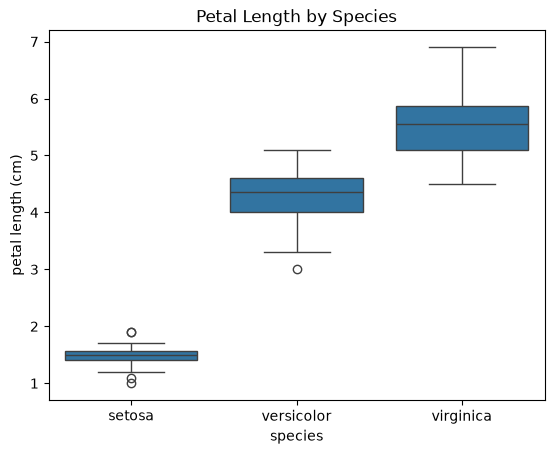

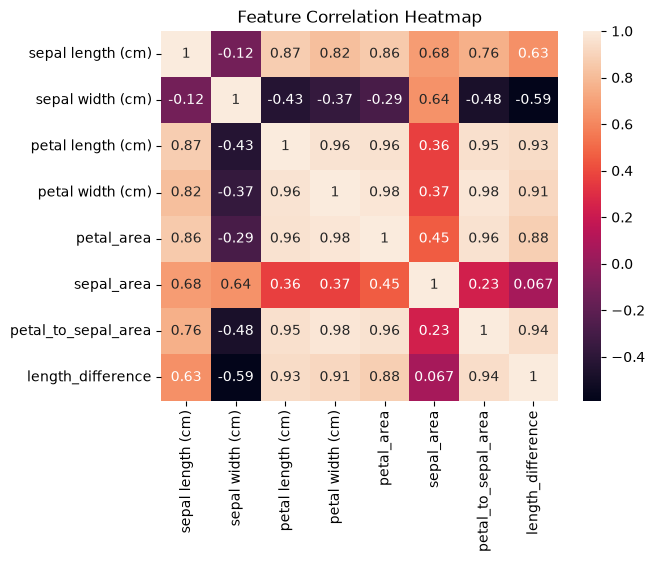

In [ ]:
# 7. Create one Seaborn boxplot and one Seaborn heatmap.

import seaborn as sns

sns.boxplot(
    x="species",
    y="petal length (cm)",
    data=df
)

plt.title("Petal Length by Species")
plt.show()


numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [35]:
# 8. Create or improve an OOP class with at least four methods.
class IrisAnalyzer:

    def __init__(self, dataframe):
        self.df = dataframe

    def show_summary(self):
        return self.df.describe()

    def show_shape(self):
        return self.df.shape

    def filter_species(self, species):
        return self.df[self.df["species"] == species]

    def average_by_species(self):
        return self.df.groupby("species")[
            ["sepal length (cm)", "petal length (cm)"]
        ].mean()

In [38]:
analyzer = IrisAnalyzer(df)

analyzer.show_summary()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),petal_area,sepal_area,petal_to_sepal_area,length_difference
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,5.794067,17.822867,0.314798,-2.085333
std,0.828066,0.435866,1.765298,0.762238,4.712390,3.361854,0.235942,1.119527
min,4.300000,2.000000,1.000000,0.100000,0.110000,10.000000,0.007036,-4.600000
25%,5.100000,2.800000,1.600000,0.300000,0.420000,15.660000,0.023640,-3.200000
50%,5.800000,3.000000,4.350000,1.300000,5.615000,17.660000,0.336696,-1.700000
75%,6.400000,3.300000,5.100000,1.800000,9.690000,20.325000,0.515812,-1.200000
max,7.900000,4.400000,6.900000,2.500000,15.870000,30.020000,0.792707,-0.300000


In [39]:
analyzer.show_shape()

(150, 9)

In [40]:
analyzer.filter_species("setosa")

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,petal_area,sepal_area,petal_to_sepal_area,length_difference
0,5.1,3.5,1.4,0.2,setosa,0.28,17.85,0.015686,-3.7
1,4.9,3.0,1.4,0.2,setosa,0.28,14.70,0.019048,-3.5
2,4.7,3.2,1.3,0.2,setosa,0.26,15.04,0.017287,-3.4
3,4.6,3.1,1.5,0.2,setosa,0.30,14.26,0.021038,-3.1
4,5.0,3.6,1.4,0.2,setosa,0.28,18.00,0.015556,-3.6
5,5.4,3.9,1.7,0.4,setosa,0.68,21.06,0.032289,-3.7
6,4.6,3.4,1.4,0.3,setosa,0.42,15.64,0.026854,-3.2
7,5.0,3.4,1.5,0.2,setosa,0.30,17.00,0.017647,-3.5
8,4.4,2.9,1.4,0.2,setosa,0.28,12.76,0.021944,-3.0
9,4.9,3.1,1.5,0.1,setosa,0.15,15.19,0.009875,-3.4


In [41]:
analyzer.average_by_species()

,sepal length (cm),petal length (cm)
species,,
setosa,5.006,1.462
versicolor,5.936,4.260
virginica,6.588,5.552


# 9. Write two short paragraphs: one about the most important data pattern and one about how this lab prepares you for future AI topics.

### Most Important Data Pattern

<!-- The most important pattern in the Iris dataset is that petal measurements differ clearly between species. Setosa generally has much smaller petal length and width than versicolor and virginica. The scatter plot and boxplot make these differences easy to see, while the groupby results allow the average measurements of each species to be compared. -->

### Preparation for Future AI Topics

<!-- This lab prepares me for future AI topics by giving me practice with loading, cleaning, exploring, filtering, and visualizing data. These skills are important before building machine learning and AI models because understanding the dataset helps identify patterns, relationships, and potential problems before training a model. -->